**1) Checking GPU and Tensorflow**

In [ ]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**2) Connect Kaggle Token**

In [ ]:
import os
from google.colab import userdata
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("Kaggle API token loaded successfully.")

Kaggle API token loaded successfully.


**3) Install Kaggle**

In [ ]:
!pip -q install kaggle
!kaggle --version

Kaggle CLI 2.0.2


**4) Downloading ASL Alphabet Dataset**

In [ ]:
!mkdir -p /content/asl_dataset

!kaggle datasets download \
    -d grassknoted/asl-alphabet \
    -p /content/asl_dataset \
    --unzip
import os

print("Files/Folders in dataset:")
print(os.listdir("/content/asl_dataset"))

Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
100% 1.03G/1.03G [00:27<00:00, 40.6MB/s]

Files/Folders in dataset:
['asl_alphabet_train', 'asl_alphabet_test']


**5) Finding Training Folder**

In [ ]:
import os

base_path = "/content/asl_dataset"

for root, dirs, files in os.walk(base_path):

    if "A" in dirs:
        print("Possible training dataset folder:")
        print(root)
        break

Possible training dataset folder:
/content/asl_dataset/asl_alphabet_train/asl_alphabet_train


**6) Setting Dataset Path**

In [ ]:
DATA_DIR = "/content/asl_dataset/asl_alphabet_train/asl_alphabet_train"
print("Dataset path:", DATA_DIR)
print("Classes/Folders:", os.listdir(DATA_DIR)[:10])

Dataset path: /content/asl_dataset/asl_alphabet_train/asl_alphabet_train
Classes/Folders: ['B', 'Q', 'O', 'A', 'G', 'I', 'L', 'P', 'Y', 'X']


**7) Importing all Project Libraries**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully.")

All libraries imported successfully.


**8) Project Configuration**

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Image Size :", IMG_SIZE)
print("Batch Size :", BATCH_SIZE)
print("Random Seed:", SEED)

Image Size : (224, 224)
Batch Size : 32
Random Seed: 42


**9) Finding all the class labels**

In [ ]:
class_names = sorted([
    folder
    for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
])

NUM_CLASSES = len(class_names)

print("Number of Classes:", NUM_CLASSES)
print("\nClasses:")
print(class_names)

Number of Classes: 29

Classes:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


**10) Count images in every class**

In [ ]:
class_counts = {}

for class_name in class_names:

    class_path = os.path.join(
        DATA_DIR,
        class_name
    )

    image_count = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith((
            ".jpg", ".jpeg", ".png"
        ))
    ])

    class_counts[class_name] = image_count

class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image_Count"]
)

print(class_counts_df)

      Class  Image_Count
0         A         3000
1         B         3000
2         C         3000
3         D         3000
4         E         3000
5         F         3000
6         G         3000
7         H         3000
8         I         3000
9         J         3000
10        K         3000
11        L         3000
12        M         3000
13        N         3000
14        O         3000
15        P         3000
16        Q         3000
17        R         3000
18        S         3000
19        T         3000
20        U         3000
21        V         3000
22        W         3000
23        X         3000
24        Y         3000
25        Z         3000
26      del         3000
27  nothing         3000
28    space         3000


**11) Dataset distribution graph**

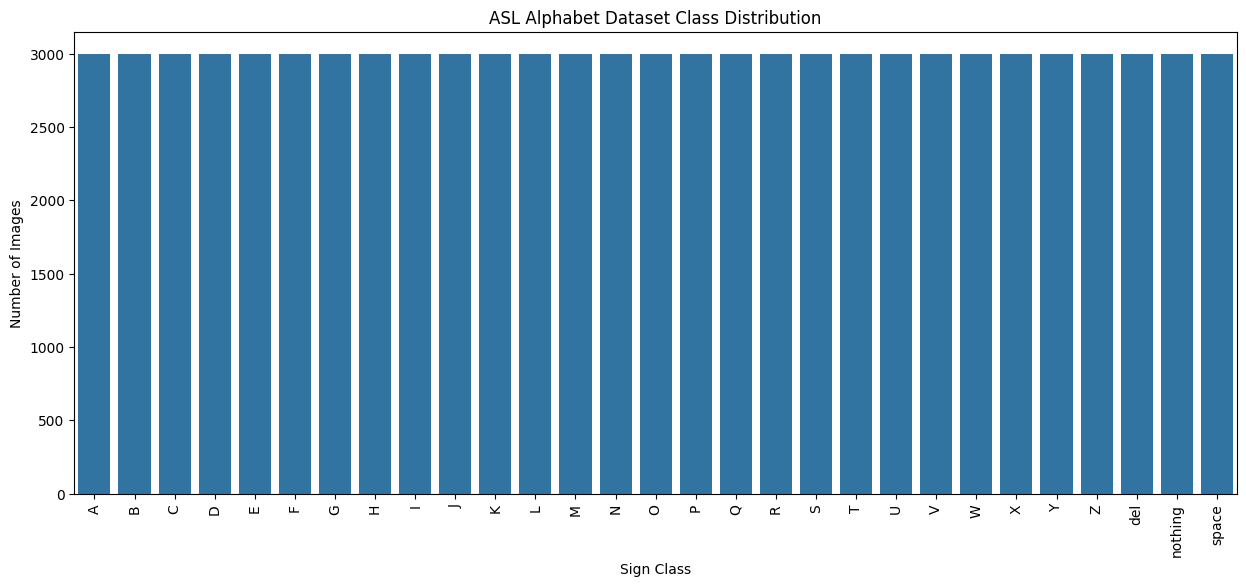

In [ ]:
plt.figure(figsize=(15, 6))

sns.barplot(
    data=class_counts_df,
    x="Class",
    y="Image_Count"
)

plt.title("ASL Alphabet Dataset Class Distribution")
plt.xlabel("Sign Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)

plt.show()

**12) Display sample images**

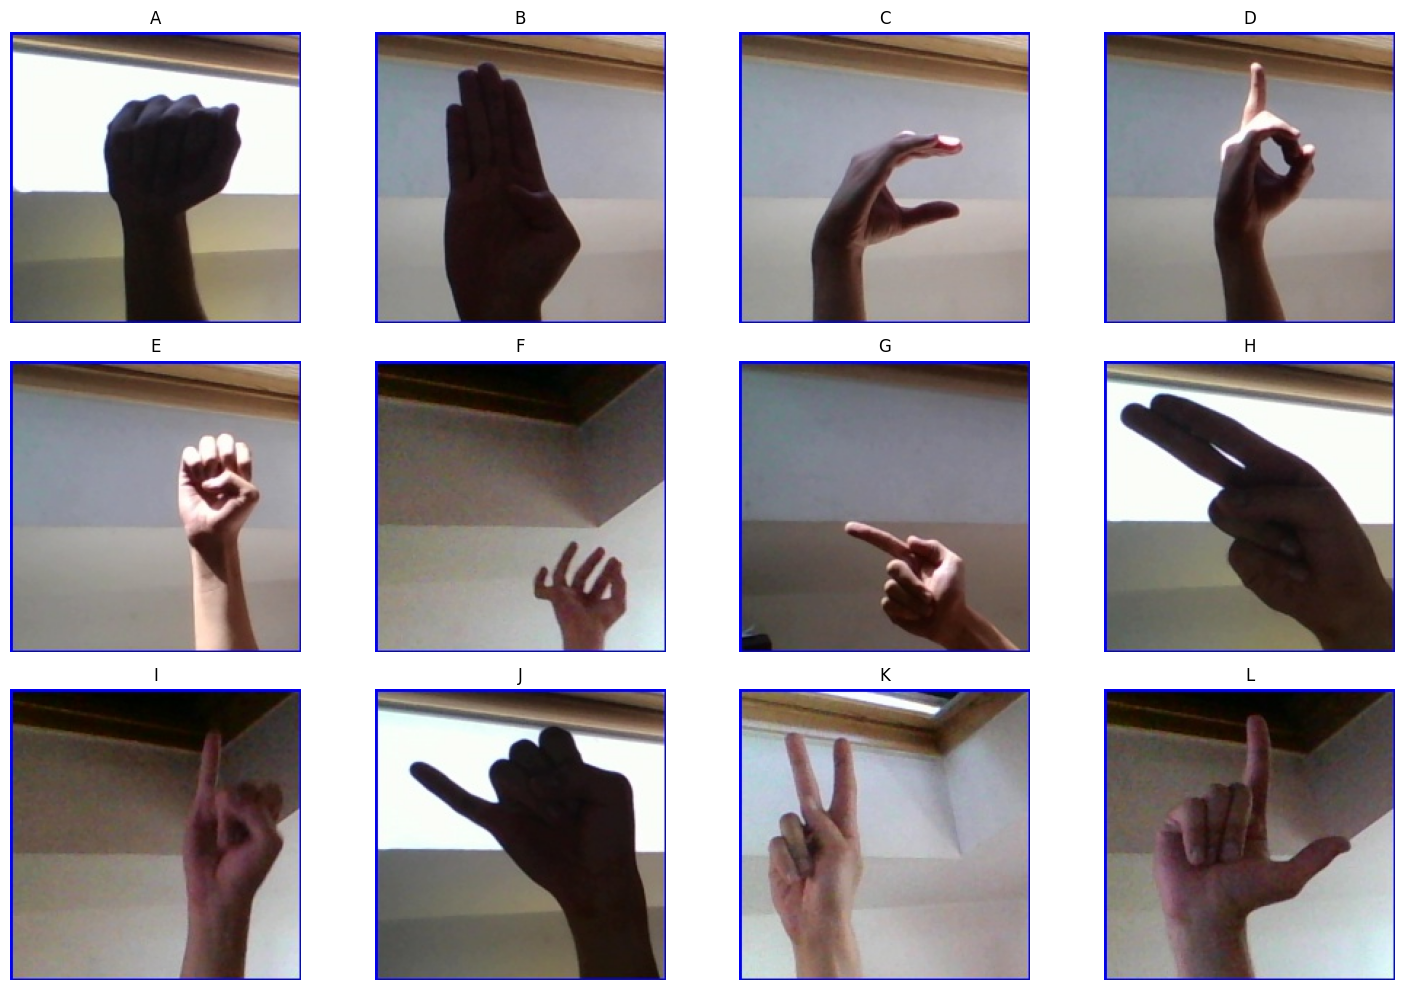

In [ ]:
plt.figure(figsize=(15, 10))

for i, class_name in enumerate(class_names[:12]):

    class_path = os.path.join(
        DATA_DIR,
        class_name
    )

    image_files = os.listdir(class_path)

    image_path = os.path.join(
        class_path,
        image_files[0]
    )

    image = tf.keras.utils.load_img(
        image_path
    )

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

**13) Create training dataset**

In [ ]:
train_dataset = tf.keras.utils.image_dataset_from_directory(

    DATA_DIR,

    validation_split=0.20,

    subset="training",

    seed=SEED,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="int"
)

print("Training dataset created.")

Found 87000 files belonging to 29 classes.
Using 69600 files for training.
Training dataset created.


**14) Create validation dataset**

In [ ]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(

    DATA_DIR,

    validation_split=0.20,

    subset="validation",

    seed=SEED,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    label_mode="int"
)

print("Validation dataset created.")

Found 87000 files belonging to 29 classes.
Using 17400 files for validation.
Validation dataset created.


**15) Check dataset sizes**

In [ ]:
train_batches = tf.data.experimental.cardinality(
    train_dataset
).numpy()

validation_batches = tf.data.experimental.cardinality(
    validation_dataset
).numpy()

print("Training Batches  :", train_batches)
print("Validation Batches:", validation_batches)

Training Batches  : 2175
Validation Batches: 544


**16) Optimize input pipeline**

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(
    AUTOTUNE
)

validation_dataset = validation_dataset.prefetch(
    AUTOTUNE
)

print("Input pipeline optimized.")

Input pipeline optimized.


**17) Data augmentation**

In [ ]:
data_augmentation = keras.Sequential([

    layers.RandomRotation(0.08),

    layers.RandomZoom(0.10),

    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),

    layers.RandomContrast(0.10)

])

print("Data augmentation created.")

Data augmentation created.


**18) Load ResNet50**

In [ ]:
base_model = ResNet50(

    weights="imagenet",

    include_top=False,

    input_shape=(224, 224, 3)

)

base_model.trainable = False

print("ResNet50 loaded.")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
ResNet50 loaded.


**19) Build our complete model**

In [ ]:
inputs = keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = keras.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 29)        │      7,453 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,127,901 (92.04 MB)

 Trainable params: 536,093 (2.05 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

**20) Compile model**

In [ ]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model compiled successfully.")

Model compiled successfully.


**21) Configure callbacks**

In [ ]:
callbacks = [

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),

    keras.callbacks.ModelCheckpoint(
        "/content/best_sign_model.keras",
        monitor="val_accuracy",
        save_best_only=True
    )

]

print("Callbacks configured.")

Callbacks configured.


**22) Train the model**

In [ ]:
EPOCHS = 5

history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=EPOCHS,

    callbacks=callbacks

)

Epoch 1/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 417s 185ms/step - accuracy: 0.7582 - loss: 0.7985 - val_accuracy: 0.9425 - val_loss: 0.1673 - learning_rate: 0.0010
Epoch 2/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 394s 181ms/step - accuracy: 0.8629 - loss: 0.4223 - val_accuracy: 0.9502 - val_loss: 0.1414 - learning_rate: 0.0010
Epoch 3/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 403s 185ms/step - accuracy: 0.8807 - loss: 0.3629 - val_accuracy: 0.9598 - val_loss: 0.1081 - learning_rate: 0.0010
Epoch 4/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 395s 182ms/step - accuracy: 0.8933 - loss: 0.3279 - val_accuracy: 0.9688 - val_loss: 0.0848 - learning_rate: 0.0010
Epoch 5/5
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 403s 185ms/step - accuracy: 0.9025 - loss: 0.3030 - val_accuracy: 0.9751 - val_loss: 0.0725 - learning_rate: 0.0010


**23) Plot accuracy and Loss**

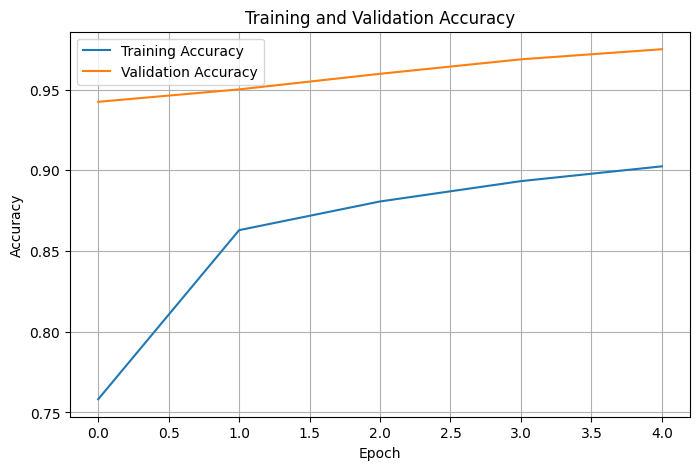

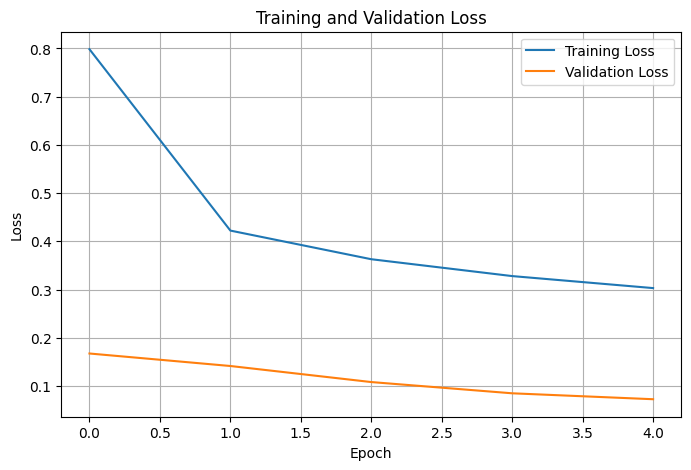

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

**24) Evaluate Model**

In [ ]:
loss, accuracy = model.evaluate(
    validation_dataset
)

print("\nMODEL PERFORMANCE")
print("------------------------")
print("Validation Loss     :", round(loss, 4))
print("Validation Accuracy :", round(accuracy * 100, 2), "%")

544/544 ━━━━━━━━━━━━━━━━━━━━ 75s 138ms/step - accuracy: 0.9751 - loss: 0.0725

MODEL PERFORMANCE
------------------------
Validation Loss     : 0.0725
Validation Accuracy : 97.51 %


**25) Generate predictions**

In [ ]:
y_true = []
y_pred = []

for images, labels in validation_dataset:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_labels
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Predictions generated.")

Predictions generated.


**26) Classification report**

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

           A     0.9424    0.9984    0.9696       623
           B     0.9937    0.9890    0.9913       634
           C     1.0000    0.9967    0.9983       601
           D     0.9907    0.9922    0.9915       643
           E     0.9829    0.9453    0.9637       548
           F     1.0000    0.9814    0.9906       646
           G     0.9919    0.9967    0.9943       612
           H     0.9968    0.9920    0.9944       626
           I     0.9884    0.9786    0.9834       607
           J     0.9823    0.9744    0.9783       626
           K     0.9466    0.9928    0.9691       553
           L     0.9933    0.9966    0.9949       593
           M     0.9842    0.9461    0.9648       594
           N     0.9427    0.9784    0.9602       555
           O     0.9882    0.9866    0.9874       595
           P     0.9966    0.9818    0.9892       606
           Q     0.9739    0.9984    0.9860       636
           R     0.9439    

**27) Confusion Matrix**

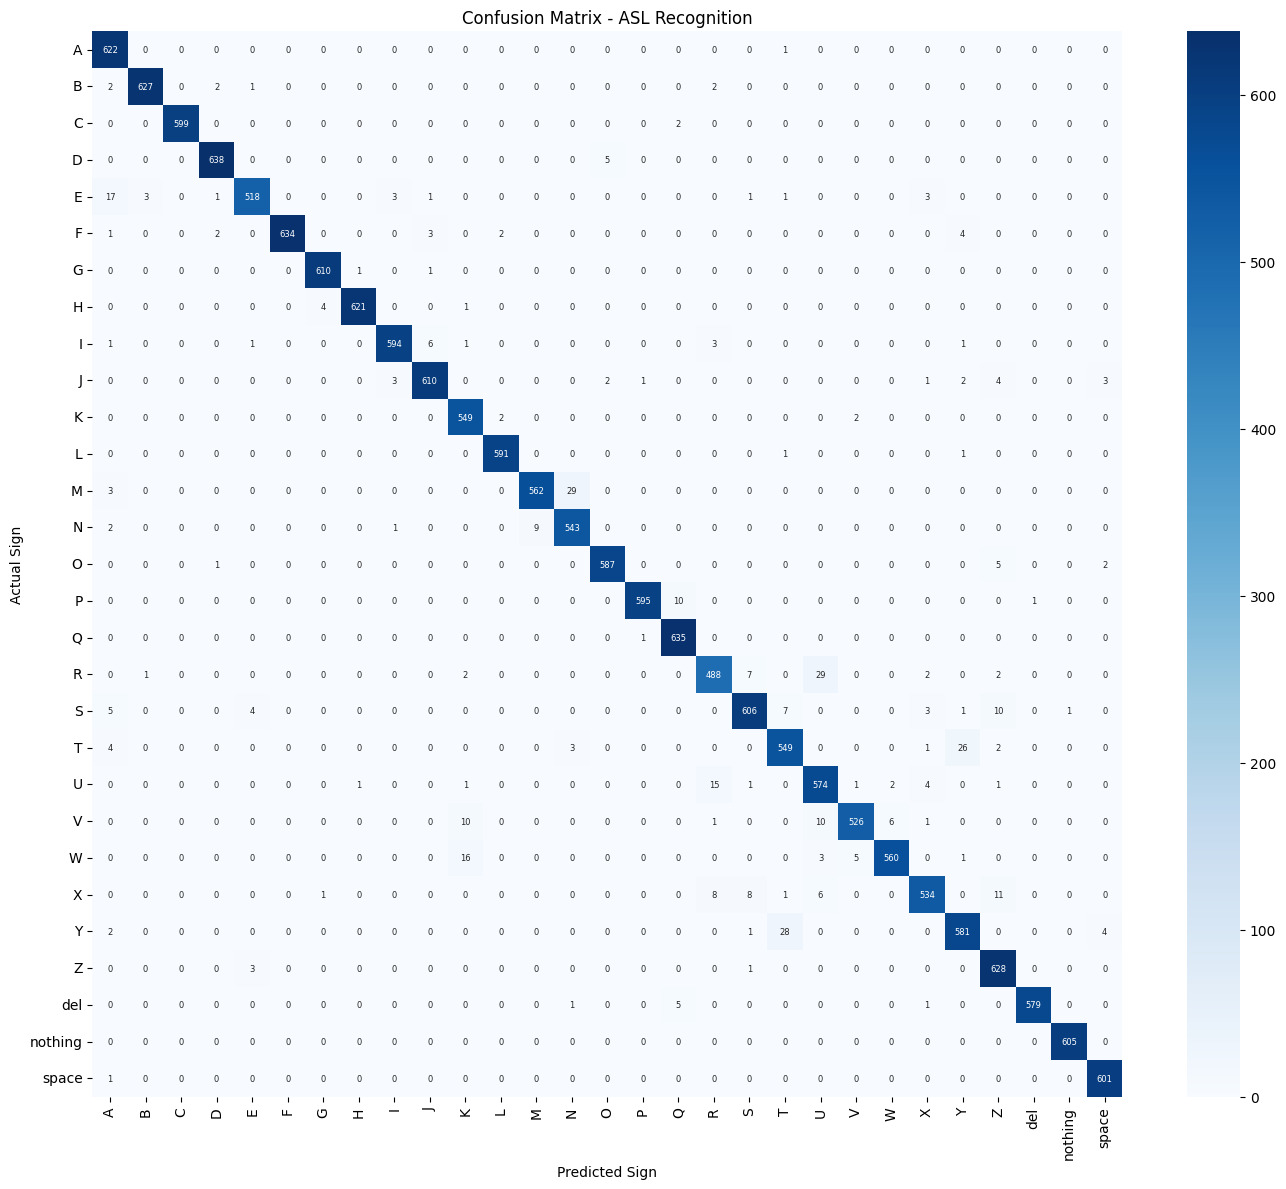

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 6}
)

plt.title(
    "Confusion Matrix - ASL Recognition"
)

plt.xlabel("Predicted Sign")
plt.ylabel("Actual Sign")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**28) Fine-tune ResNet50**

In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

print("ResNet50 fine-tuning enabled.")

ResNet50 fine-tuning enabled.


**29) Recompile with smaller learning rate**

In [ ]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


**30) Fine-tune**

In [ ]:
fine_tune_history = model.fit(

    train_dataset,

    validation_data=validation_dataset,

    epochs=2,

    callbacks=callbacks

)

Epoch 1/2
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 521s 233ms/step - accuracy: 0.9402 - loss: 0.1816 - val_accuracy: 0.9906 - val_loss: 0.0257 - learning_rate: 1.0000e-05
Epoch 2/2
2175/2175 ━━━━━━━━━━━━━━━━━━━━ 505s 232ms/step - accuracy: 0.9742 - loss: 0.0783 - val_accuracy: 0.9955 - val_loss: 0.0149 - learning_rate: 1.0000e-05


**31) Final performance**

In [ ]:
final_loss, final_accuracy = model.evaluate(
    validation_dataset
)

print("\nFINAL MODEL PERFORMANCE")
print("========================")

print(
    "Final Loss     :",
    round(final_loss, 4)
)

print(
    "Final Accuracy :",
    round(final_accuracy * 100, 2),
    "%"
)

544/544 ━━━━━━━━━━━━━━━━━━━━ 75s 138ms/step - accuracy: 0.9955 - loss: 0.0149

FINAL MODEL PERFORMANCE
Final Loss     : 0.0149
Final Accuracy : 99.55 %


**32) Upload YOUR sign image**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving WIN_20261004_12_54_46_Pro.jpg to WIN_20261004_12_54_46_Pro.jpg


**33) Predict your image**

In [ ]:
image_path = list(uploaded.keys())[0]

image = tf.keras.utils.load_img(
    image_path,
    target_size=IMG_SIZE
)

image_array = tf.keras.utils.img_to_array(
    image
)

image_array = np.expand_dims(
    image_array,
    axis=0
)

prediction = model.predict(
    image_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index] * 100
)

print("Predicted Sign :", predicted_class)
print(
    "Confidence     :",
    round(confidence, 2),
    "%"
)

Predicted Sign : L
Confidence     : 100.0 %


**34) Display prediction**

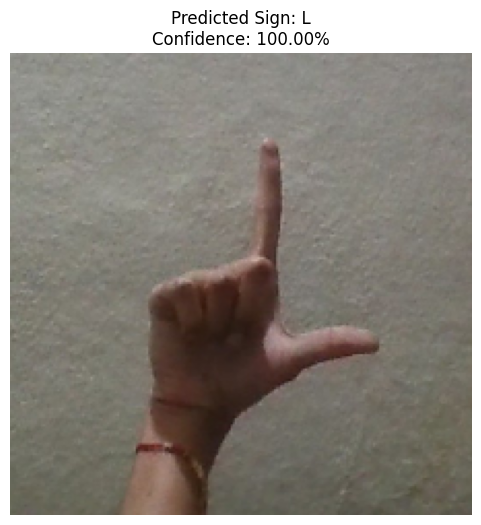

In [ ]:
plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.axis("off")

plt.title(
    f"Predicted Sign: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

**35) Show Top-5 predictions**

In [ ]:
top_indices = np.argsort(
    prediction[0]
)[-5:][::-1]

print("TOP 5 PREDICTIONS")
print("==================")

for rank, index in enumerate(
    top_indices,
    start=1
):

    label = class_names[index]

    probability = (
        prediction[0][index] * 100
    )

    print(
        f"{rank}. {label:10s} "
        f"{probability:.2f}%"
    )

TOP 5 PREDICTIONS
1. L          100.00%
2. V          0.00%
3. Z          0.00%
4. Y          0.00%
5. T          0.00%


**36) Save trained model**

In [ ]:
model.save(
    "/content/Sign_Language_ResNet50.keras"
)

print(
    "Model saved successfully."
)

Model saved successfully.


**37) Download Trained Model**

In [ ]:
files.download(
    "/content/Sign_Language_ResNet50.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>